# Clustering demo: K-means, GMM and agglomerative clustering

Run the cell below (it takes a few seconds). See `README.md` for how to read the results and things to try.

K-means               silhouette = 0.588
GMM                   silhouette = 0.568
Agglomerative (Ward)  silhouette = 0.568

GMM probabilities of the first 5 points (one column per cluster):
 [[0. 1. 0.]
 [0. 1. 0.]
 [0. 1. 0.]
 [0. 0. 1.]
 [1. 0. 0.]]


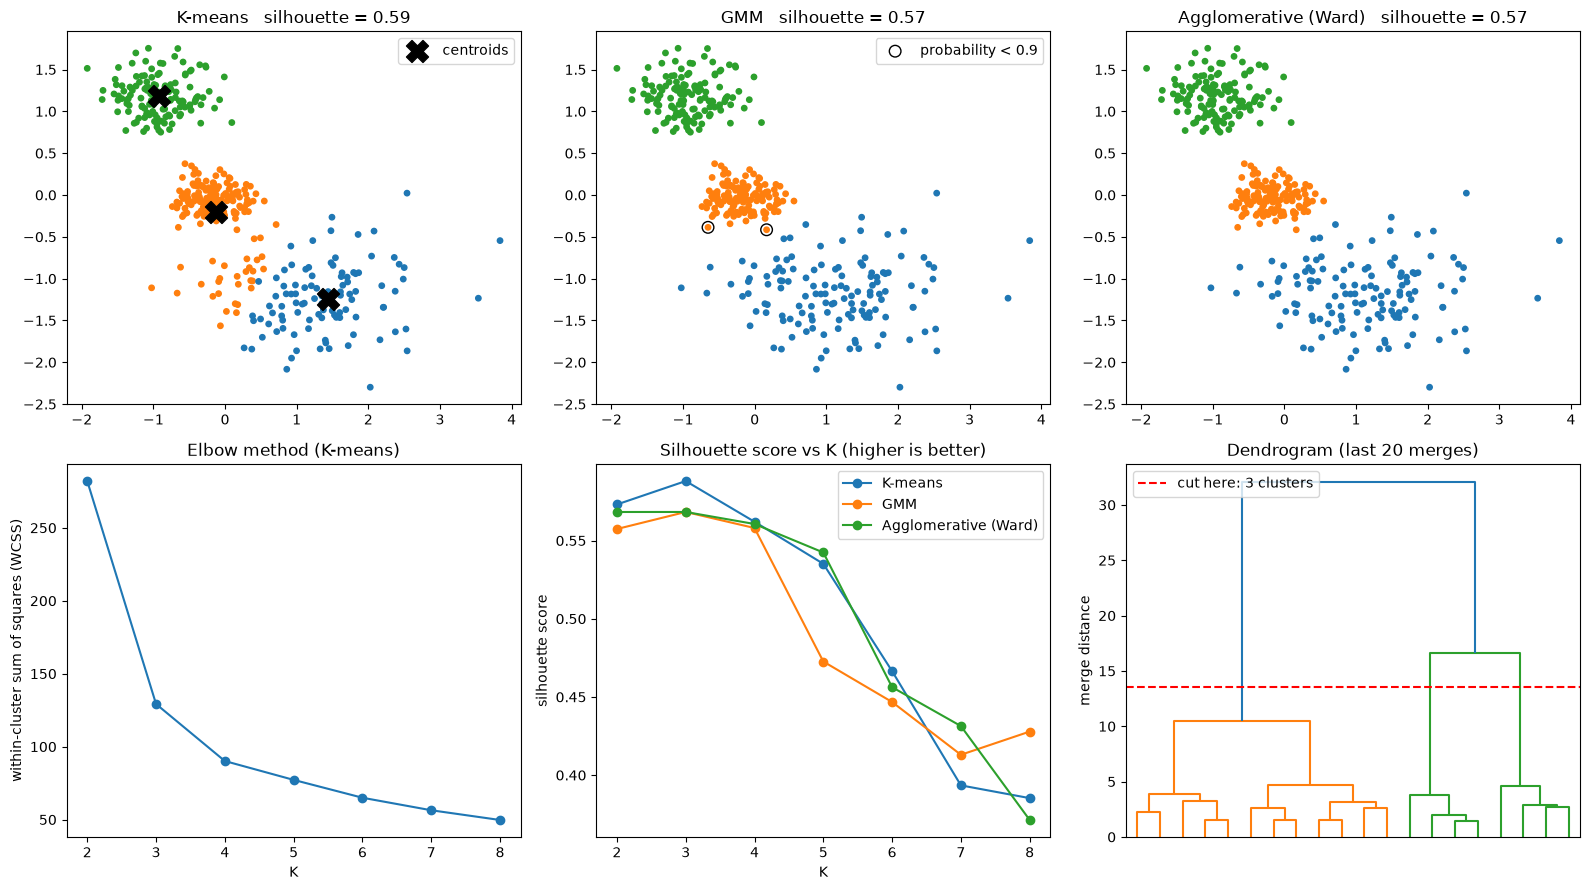

In [1]:
# Clustering demo: K-means, GMM and Agglomerative clustering, evaluated with the silhouette score
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

# 1. Data: 400 unlabelled 2-D points from 3 groups with different spreads, then standardized (mean 0, std 1)
X, _ = make_blobs(n_samples=400, centers=3, cluster_std=[0.8, 1.6, 0.6], random_state=36)
X = StandardScaler().fit_transform(X)

# 2. Cluster with K = 3
K = 3
LINKAGE = "ward"   # for agglomerative clustering: "ward", "single", "average" or "complete"
kmeans = KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=0).fit(X)
gmm = GaussianMixture(n_components=K, random_state=0).fit(X)
agglo = AgglomerativeClustering(n_clusters=K, linkage=LINKAGE)
labels = {"K-means": kmeans.labels_,
          "GMM": gmm.predict(X),
          f"Agglomerative ({LINKAGE.capitalize()})": agglo.fit_predict(X)}

# 3. Evaluate with the silhouette score: from -1 to 1, higher = tighter and better-separated clusters
for name, lab in labels.items():
    print(f"{name:21s} silhouette = {silhouette_score(X, lab):.3f}")
# GMM is a soft clustering: each point gets a probability for every cluster
print("\nGMM probabilities of the first 5 points (one column per cluster):\n", gmm.predict_proba(X[:5]).round(2))

# 4. Choosing K: elbow (K-means WCSS) and silhouette score for K = 2..8
ks = range(2, 9)
wcss = [KMeans(k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
sil = {"K-means": [silhouette_score(X, KMeans(k, n_init=10, random_state=0).fit_predict(X)) for k in ks],
       "GMM": [silhouette_score(X, GaussianMixture(k, random_state=0).fit(X).predict(X)) for k in ks],
       f"Agglomerative ({LINKAGE.capitalize()})": [silhouette_score(X, AgglomerativeClustering(k, linkage=LINKAGE).fit_predict(X)) for k in ks]}

# 5. Plots
def same_colours(lab):   # cluster numbers are arbitrary: renumber by height so the same group gets the same colour
    order = np.argsort([X[lab == c, 1].mean() for c in np.unique(lab)])
    return np.argsort(order)[lab]


fig, ax = plt.subplots(2, 3, figsize=(16, 9))
for a, (name, lab) in zip(ax[0], labels.items()):
    a.scatter(X[:, 0], X[:, 1], c=same_colours(lab), cmap="tab10", vmin=0, vmax=9, s=15)
    a.set_title(f"{name}   silhouette = {silhouette_score(X, lab):.2f}")
ax[0, 0].scatter(*kmeans.cluster_centers_.T, marker="X", s=250, c="black", label="centroids")
ax[0, 0].legend()
unsure = gmm.predict_proba(X).max(axis=1) < 0.9                     # soft assignment: uncertain points
ax[0, 1].scatter(*X[unsure].T, s=70, facecolors="none", edgecolors="black", label="probability < 0.9")
ax[0, 1].legend()

ax[1, 0].plot(list(ks), wcss, "o-")
ax[1, 0].set(title="Elbow method (K-means)", xlabel="K", ylabel="within-cluster sum of squares (WCSS)")
for name, s in sil.items():
    ax[1, 1].plot(list(ks), s, "o-", label=name)
ax[1, 1].set(title="Silhouette score vs K (higher is better)", xlabel="K", ylabel="silhouette score")
ax[1, 1].legend()

Z = linkage(X, method=LINKAGE)                                       # the merges agglomerative clustering makes
dendrogram(Z, truncate_mode="lastp", p=20, no_labels=True, ax=ax[1, 2])
ax[1, 2].axhline((Z[-K, 2] + Z[-K + 1, 2]) / 2, color="red", linestyle="--", label=f"cut here: {K} clusters")
ax[1, 2].set(title="Dendrogram (last 20 merges)", ylabel="merge distance")
ax[1, 2].legend(loc="upper left")
plt.tight_layout()
plt.show()